# Baselines

Naive (yesterday), seasonal naive (the same weekday last week) and a 7-day average, all through the backtest harness.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from src.data import model_series
from src.backtest import backtest, score
from src.models import naive, seasonal_naive, moving_average

FIGURES = "../reports/figures/"

In [2]:
y, usable = model_series(pd.read_parquet("../data/daily.parquet"))

models = {"naive": naive, "seasonal naive": seasonal_naive, "7-day average": moving_average}
results = {name: backtest(model, y, usable) for name, model in models.items()}
table = pd.DataFrame({name: score(r) for name, r in results.items()}).T
table.round(3)

,MAPE,MASE,MAE,origins
naive,39.833,1.768,961.471,51.0
seasonal naive,24.745,1.149,615.489,51.0
7-day average,33.020,1.228,667.962,51.0


## Error by forecast day

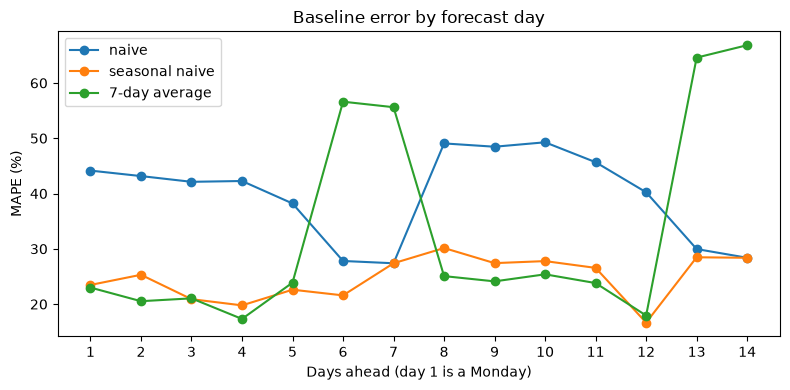

In [3]:
def ape(r):
    ok = r[r["usable"]]
    return (ok["actual"] - ok["forecast"]).abs() / ok["actual"] * 100


by_step = pd.DataFrame({name: ape(r).groupby(r.loc[r["usable"], "step"]).mean() for name, r in results.items()})

fig, ax = plt.subplots(figsize=(8, 4))
by_step.plot(ax=ax, marker="o")
ax.set_xticks(range(1, 15))
ax.set_xlabel("Days ahead (day 1 is a Monday)")
ax.set_ylabel("MAPE (%)")
ax.set_title("Baseline error by forecast day")
fig.tight_layout()
fig.savefig(FIGURES + "baselines_by_day.png", dpi=150)
plt.show()

In [4]:
by_step.round(1)

,naive,seasonal naive,7-day average
step,,,
1,44.2,23.5,23.0
2,43.2,25.3,20.5
3,42.1,20.9,21.0
4,42.3,19.8,17.3
5,38.2,22.6,23.9
6,27.8,21.6,56.6
7,27.4,27.4,55.6
8,49.1,30.1,25.1
9,48.5,27.4,24.1


The 7-day average is the best of the three on most weekdays but 56 to 67% off on weekends, because it spreads the week's average evenly over all seven days. Seasonal naive keeps the weekly shape, so it's steadier.

## Heating season

In [5]:
season = {}
for name, r in results.items():
    ok = r[r["usable"]]
    winter = ok["date"].dt.month.isin([11, 12, 1, 2, 3])
    season[name] = ape(r).groupby(winter.map({True: "Nov to Mar", False: "Apr to Oct"})).mean()
pd.DataFrame(season).T.round(1)

date,Apr to Oct,Nov to Mar
naive,40.2,39.4
seasonal naive,16.4,36.2
7-day average,32.1,34.3


Seasonal naive is 36.2% off from November to March against 16.4% for the rest of the year, probably because a cold snap in one week gets copied into the next. That's where the models have the most to gain.